Every classifier so far has drawn a boundary directly. Naive Bayes takes the opposite
route: it models **how each class generates data**, then applies Bayes' rule to invert
that into a prediction.

$$P(y \mid \mathbf{x}) = \frac{P(\mathbf{x} \mid y)\,P(y)}{P(\mathbf{x})}
\;\;\propto\;\; P(\mathbf{x}\mid y)\,P(y)$$

The obstacle is $P(\mathbf{x}\mid y)$: a joint distribution over all $p$ features needs
exponentially much data to estimate. The "naive" assumption cuts it down to size by
declaring the features **conditionally independent given the class**:

$$P(\mathbf{x}\mid y) = \prod_{j=1}^{p} P(x_j \mid y)$$

That turns one $p$-dimensional density into $p$ one-dimensional ones. The assumption is
usually false &mdash; here the two EEG features correlate above 0.9 &mdash; and the classifier
often works anyway. Section 6 shows precisely why.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


---
# 1. The Data

The same 20 EEG epochs as the Logistic Regression, KNN and SVM walkthroughs, so all four
decision boundaries can be compared on identical points.

In [2]:
# ----------------------------------------------------------------------------
#  20 EEG epochs, two features, two classes. Small enough to print in full,
#  and deliberately NOT perfectly separable.
# ----------------------------------------------------------------------------
feat2 = ["spike_rate", "line_length"]

P = np.array([
    [1.0, 12.0], [1.6, 15.0], [0.7, 11.0], [2.1, 18.0], [1.3, 14.0],
    [2.6, 21.0], [0.9, 16.0], [1.9, 13.0], [3.1, 24.0], [2.3, 17.0],
    [6.2, 41.0], [7.1, 47.0], [5.4, 38.0], [8.0, 52.0], [6.7, 44.0],
    [5.9, 49.0], [7.6, 39.0], [6.0, 35.0], [4.7, 43.0], [8.3, 46.0],
])
t2 = np.array([0]*10 + [1]*10)

# two deliberate overlaps, so no straight line separates the data perfectly
P[9]  = [4.4, 33.0]      # a class-0 epoch pushed into class-1 territory
t2[9] = 0
P[18] = [3.6, 27.0]      # a class-1 epoch pushed down toward class 0
t2[18] = 1

n2 = len(P)
ep_ids = [f"ep{i:02d}" for i in range(n2)]
cls_names = ["no seizure", "seizure"]

print(f"{n2} epochs x {P.shape[1]} features, classes {np.bincount(t2).tolist()}\n")
hdr = f"{'id':>6}  {feat2[0]:>11}  {feat2[1]:>12}  {'class':>6}  {'label':>12}"
print(hdr); print("-" * len(hdr))
for i in range(n2):
    print(f"{ep_ids[i]:>6}  {P[i,0]:>11.1f}  {P[i,1]:>12.1f}  {t2[i]:>6}  "
          f"{cls_names[t2[i]]:>12}")
print("-" * len(hdr))
print(f"\nfeature means : {np.round(P.mean(axis=0), 3)}")
print(f"feature stds  : {np.round(P.std(axis=0), 3)}")
print(f"\nNote the scales: {feat2[1]} spans ~{P[:,1].ptp() if hasattr(P[:,1],'ptp') else np.ptp(P[:,1]):.0f} "
      f"while {feat2[0]} spans ~{np.ptp(P[:,0]):.0f}.")
print("Any algorithm that measures DISTANCE will be dominated by the larger one")
print("unless the features are scaled - that matters for KNN and SVM below.")

20 epochs x 2 features, classes [10, 10]

    id   spike_rate   line_length   class         label
-------------------------------------------------------
  ep00          1.0          12.0       0    no seizure
  ep01          1.6          15.0       0    no seizure
  ep02          0.7          11.0       0    no seizure
  ep03          2.1          18.0       0    no seizure
  ep04          1.3          14.0       0    no seizure
  ep05          2.6          21.0       0    no seizure
  ep06          0.9          16.0       0    no seizure
  ep07          1.9          13.0       0    no seizure
  ep08          3.1          24.0       0    no seizure
  ep09          4.4          33.0       0    no seizure
  ep10          6.2          41.0       1       seizure
  ep11          7.1          47.0       1       seizure
  ep12          5.4          38.0       1       seizure
  ep13          8.0          52.0       1       seizure
  ep14          6.7          44.0       1       seizure
  ep15

In [3]:
def plot2d(ax=None, scaled=False, title="", legend=True):
    A = Pz if scaled else P
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(7, 5))
    for c, (col, mk) in enumerate([("steelblue", "o"), ("crimson", "^")]):
        m = t2 == c
        ax.scatter(A[m, 0], A[m, 1], c=col, marker=mk, s=90, edgecolor="k",
                   label=cls_names[c], zorder=3)
    ax.set(xlabel=feat2[0] + (" (scaled)" if scaled else ""),
           ylabel=feat2[1] + (" (scaled)" if scaled else ""), title=title)
    if legend:
        ax.legend(fontsize=8)
    ax.grid(alpha=.3)
    return ax

Pz = (P - P.mean(axis=0)) / P.std(axis=0)
print(f"correlation between the two features: {np.corrcoef(P.T)[0,1]:+.4f}")
print(f"   within class 0: {np.corrcoef(P[t2==0].T)[0,1]:+.4f}")
print(f"   within class 1: {np.corrcoef(P[t2==1].T)[0,1]:+.4f}")
print("\nNaive Bayes will assume these are ZERO. They are not. Keep that in mind")
print("for section 6, where the consequence is measured.")

correlation between the two features: +0.9621
   within class 0: +0.9489
   within class 1: +0.7524

Naive Bayes will assume these are ZERO. They are not. Keep that in mind
for section 6, where the consequence is measured.


---
# 2. Priors

$$P(y = c) = \frac{n_c}{n}$$

The prior is what the model believes before seeing any features &mdash; the base rate. On
badly imbalanced data it dominates: if a condition affects 1 in 1000, the evidence must
be strong to overcome a prior of 0.001.

In [4]:
counts = np.bincount(t2, minlength=2)
priors = counts / n2

print(f"{'class':>14}  {'count':>7}  {'prior':>9}  {'log prior':>11}")
print("-" * 46)
for c in range(2):
    print(f"{cls_names[c]:>14}  {counts[c]:>7}  {priors[c]:>9.6f}  {np.log(priors[c]):>11.6f}")
print("-" * 46)
print(f"{'total':>14}  {counts.sum():>7}  {priors.sum():>9.6f}")
print(f"\nBalanced here, so the prior will not decide anything. The formulas below")
print(f"keep it explicit anyway, because on imbalanced data it does the deciding.")

         class    count      prior    log prior
----------------------------------------------
    no seizure       10   0.500000    -0.693147
       seizure       10   0.500000    -0.693147
----------------------------------------------
         total       20   1.000000

Balanced here, so the prior will not decide anything. The formulas below
keep it explicit anyway, because on imbalanced data it does the deciding.


---
# 3. Per-Feature Likelihoods

For continuous features, **Gaussian** Naive Bayes fits one normal distribution per
(feature, class) pair:

$$P(x_j \mid y=c) = \frac{1}{\sqrt{2\pi\sigma_{jc}^2}}
\exp\!\left(-\frac{(x_j - \mu_{jc})^2}{2\sigma_{jc}^2}\right)$$

With $p$ features and $k$ classes that is $2pk$ numbers &mdash; here $2 \times 2 \times 2 = 8$.
Modelling the full joint would instead require a $2\times2$ covariance matrix per class,
and in higher dimensions the gap becomes the whole argument for the method.

Note the variance is the **maximum-likelihood** one (divide by $n_c$, not $n_c - 1$),
which is what scikit-learn uses.

In [5]:
means = np.zeros((2, 2))
varis = np.zeros((2, 2))
for c in range(2):
    Ac = Pz[t2 == c]
    means[c] = Ac.mean(axis=0)
    varis[c] = Ac.var(axis=0)           # ddof=0, the MLE

print("fitted parameters (standardised features)\n")
print(f"{'class':>14}  {'feature':>12}  {'mu':>11}  {'sigma^2':>11}  {'sigma':>10}")
print("-" * 64)
for c in range(2):
    for j in range(2):
        print(f"{cls_names[c]:>14}  {feat2[j]:>12}  {means[c,j]:>11.6f}  "
              f"{varis[c,j]:>11.6f}  {np.sqrt(varis[c,j]):>10.6f}")
print("-" * 64)

print(f"\nby hand, mu for class 0 / {feat2[0]}:")
vals = Pz[t2 == 0][:, 0]
print(f"   ({' + '.join(f'{v:+.3f}' for v in vals[:5])} + ...) / {len(vals)}")
print(f"   = {vals.sum():.6f} / {len(vals)} = {vals.mean():.6f}")
print(f"   from the table: {means[0,0]:.6f}   MATCH: {np.isclose(vals.mean(), means[0,0])}")
print(f"\n   sigma^2 = sum (x - mu)^2 / n_c")
sq = (vals - vals.mean())**2
print(f"           = ({' + '.join(f'{v:.3f}' for v in sq[:5])} + ...) / {len(vals)}")
print(f"           = {sq.sum():.6f} / {len(vals)} = {sq.mean():.6f}")
print(f"   from the table: {varis[0,0]:.6f}   MATCH: {np.isclose(sq.mean(), varis[0,0])}")

print(f"\n\ntotal parameters: 2 classes x 2 features x (mu, sigma^2) = 8, plus 2 priors")
print(f"a full joint Gaussian would need 2 classes x (2 means + 3 covariance terms) = 10")
print(f"at p = 100 features: naive needs {2*100*2} numbers, full joint needs "
      f"{2*(100 + 100*101//2):,}")

fitted parameters (standardised features)

         class       feature           mu      sigma^2       sigma
----------------------------------------------------------------
    no seizure    spike_rate    -0.881536     0.180811    0.425219
    no seizure   line_length    -0.873538     0.214465    0.463104
       seizure    spike_rate     0.881536     0.264979    0.514761
       seizure   line_length     0.873538     0.259397    0.509310
----------------------------------------------------------------

by hand, mu for class 0 / spike_rate:
   (-1.256 + -1.022 + -1.373 + -0.827 + -1.139 + ...) / 10
   = -8.815356 / 10 = -0.881536
   from the table: -0.881536   MATCH: True

   sigma^2 = sum (x - mu)^2 / n_c
           = (0.140 + 0.020 + 0.242 + 0.003 + 0.066 + ...) / 10
           = 1.808112 / 10 = 0.180811
   from the table: 0.180811   MATCH: True


total parameters: 2 classes x 2 features x (mu, sigma^2) = 8, plus 2 priors
a full joint Gaussian would need 2 classes x (2 means + 3 cova

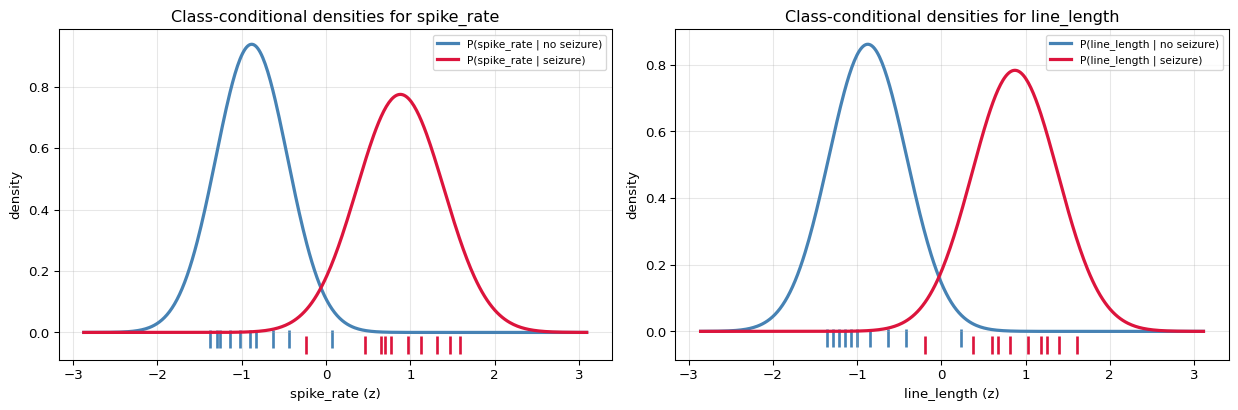

Each panel is one row of the parameter table above. Naive Bayes multiplies
these two panels together and never asks whether that is legitimate.


In [6]:
def gauss_pdf(x, m, v):
    return np.exp(-((x - m)**2) / (2*v)) / np.sqrt(2*np.pi*v)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for j, ax in enumerate(axes):
    g = np.linspace(Pz[:,j].min()-1.5, Pz[:,j].max()+1.5, 400)
    for c, col in enumerate(["steelblue", "crimson"]):
        ax.plot(g, gauss_pdf(g, means[c,j], varis[c,j]), lw=2.4, color=col,
                label=f"P({feat2[j]} | {cls_names[c]})")
        ax.scatter(Pz[t2==c, j], np.zeros((t2==c).sum())-0.02*(c+1),
                   marker="|", s=180, color=col, linewidths=2)
    ax.set(xlabel=feat2[j]+" (z)", ylabel="density",
           title=f"Class-conditional densities for {feat2[j]}")
    ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Each panel is one row of the parameter table above. Naive Bayes multiplies")
print("these two panels together and never asks whether that is legitimate.")

---
# 4. Classifying One Point, By Hand

Work in **log space**. Multiplying many small probabilities underflows to zero in
floating point; adding logs does not, and the arg max is unchanged:

$$\log P(y=c\mid\mathbf{x}) = \log P(y=c) + \sum_j \log P(x_j\mid y=c) - \log P(\mathbf{x})$$

The last term is the same for every class, so it can be ignored for the decision &mdash; but
it is needed to turn the scores back into probabilities.

In [7]:
i = 9                                   # one of the planted overlaps
x = Pz[i]
print(f"classifying {ep_ids[i]}: {feat2[0]}_z = {x[0]:+.4f}, "
      f"{feat2[1]}_z = {x[1]:+.4f}   (true class {t2[i]})\n")

log_post = np.zeros(2)
for c in range(2):
    print(f"--- class {c} ({cls_names[c]}) ---")
    lp = np.log(priors[c])
    print(f"   log P(y={c})                 = log({priors[c]:.4f}) = {lp:+.6f}")
    tot = lp
    for j in range(2):
        d = gauss_pdf(x[j], means[c,j], varis[c,j])
        ld = np.log(d)
        print(f"   P({feat2[j]}={x[j]:+.3f} | y={c})")
        print(f"      = exp(-({x[j]:+.4f} - {means[c,j]:+.4f})^2 / "
              f"(2*{varis[c,j]:.4f})) / sqrt(2*pi*{varis[c,j]:.4f})")
        print(f"      = {d:.8f}      log = {ld:+.6f}")
        tot += ld
    log_post[c] = tot
    print(f"   log posterior (unnormalised) = {tot:+.6f}\n")

m_ = log_post.max()
post = np.exp(log_post - m_)
post /= post.sum()
print(f"normalising with the log-sum-exp trick (max = {m_:+.6f}):")
for c in range(2):
    print(f"   class {c}: exp({log_post[c]:+.6f} - ({m_:+.6f})) = "
          f"{np.exp(log_post[c]-m_):.8f}")
print(f"   sum = {np.exp(log_post - m_).sum():.8f}")
for c in range(2):
    print(f"   P(y={c} | x) = {post[c]:.8f}")
print(f"\nprediction: class {int(np.argmax(post))}   true: {t2[i]}   "
      f"{'correct' if np.argmax(post)==t2[i] else 'WRONG'}")

classifying ep09: spike_rate_z = +0.0702, line_length_z = +0.2356   (true class 0)

--- class 0 (no seizure) ---
   log P(y=0)                 = log(0.5000) = -0.693147
   P(spike_rate=+0.070 | y=0)
      = exp(-(+0.0702 - -0.8815)^2 / (2*0.1808)) / sqrt(2*pi*0.1808)
      = 0.07663754      log = -2.568668
   P(line_length=+0.236 | y=0)
      = exp(-(+0.2356 - -0.8735)^2 / (2*0.2145)) / sqrt(2*pi*0.2145)
      = 0.04893898      log = -3.017181
   log posterior (unnormalised) = -6.278997

--- class 1 (seizure) ---
   log P(y=1)                 = log(0.5000) = -0.693147
   P(spike_rate=+0.070 | y=1)
      = exp(-(+0.0702 - +0.8815)^2 / (2*0.2650)) / sqrt(2*pi*0.2650)
      = 0.22380903      log = -1.496962
   P(line_length=+0.236 | y=1)
      = exp(-(+0.2356 - +0.8735)^2 / (2*0.2594)) / sqrt(2*pi*0.2594)
      = 0.35747798      log = -1.028682
   log posterior (unnormalised) = -3.218791

normalising with the log-sum-exp trick (max = -3.218791):
   class 0: exp(-6.278997 - (-3.218791)) = 

In [8]:
def nb_log_posterior(A):
    out = np.zeros((len(A), 2))
    for c in range(2):
        lp = np.log(priors[c])
        ll = -((A - means[c])**2) / (2*varis[c]) - 0.5*np.log(2*np.pi*varis[c])
        out[:, c] = lp + ll.sum(axis=1)
    return out

lpost = nb_log_posterior(Pz)
probs = np.exp(lpost - lpost.max(axis=1, keepdims=True))
probs /= probs.sum(axis=1, keepdims=True)
pred = probs.argmax(axis=1)

print(f"{'id':>6}  {'log P(.|0)':>12}  {'log P(.|1)':>12}  {'P(y=1|x)':>10}  "
      f"{'pred':>5}  {'true':>5}  {'ok':>4}")
print("-" * 64)
for k in range(n2):
    print(f"{ep_ids[k]:>6}  {lpost[k,0]:>12.5f}  {lpost[k,1]:>12.5f}  "
          f"{probs[k,1]:>10.6f}  {pred[k]:>5}  {t2[k]:>5}  "
          f"{'yes' if pred[k]==t2[k] else 'NO':>4}")
print("-" * 64)
print(f"\naccuracy: {(pred==t2).mean():.4f}  ({(pred==t2).sum()}/{n2})")
print(f"misclassified: {[ep_ids[k] for k in np.where(pred!=t2)[0]]}")

    id    log P(.|0)    log P(.|1)    P(y=1|x)   pred   true    ok
----------------------------------------------------------------
  ep00      -1.69188     -18.80931    0.000000      0      0   yes
  ep01      -1.04991     -15.30473    0.000001      0      0   yes
  ep02      -2.12401     -20.39297    0.000000      0      0   yes
  ep03      -0.91542     -12.43781    0.000010      0      0   yes
  ep04      -1.25707     -16.72426    0.000000      0      0   yes
  ep05      -1.21182      -9.89677    0.000169      0      0   yes
  ep06      -1.41421     -16.87400    0.000000      0      0   yes
  ep07      -1.17823     -15.61638    0.000001      0      0   yes
  ep08      -1.93913      -7.68161    0.003197      0      0   yes
  ep09      -6.27900      -3.21879    0.955221      1      0    NO
  ep10     -15.12129      -1.22126    0.999999      1      1   yes
  ep11     -22.53982      -1.57654    1.000000      1      1   yes
  ep12     -10.93375      -1.67341    0.999905      1      1   y

---
# 5. The Decision Boundary

With **equal variances across classes** the log-posterior difference is linear in
$\mathbf{x}$ and the boundary is a straight line. When the variances differ, the
quadratic terms survive and the boundary becomes a conic &mdash; a parabola, ellipse or
hyperbola.

So Gaussian Naive Bayes is a *quadratic* classifier in general, and reduces to a linear
one in a special case.

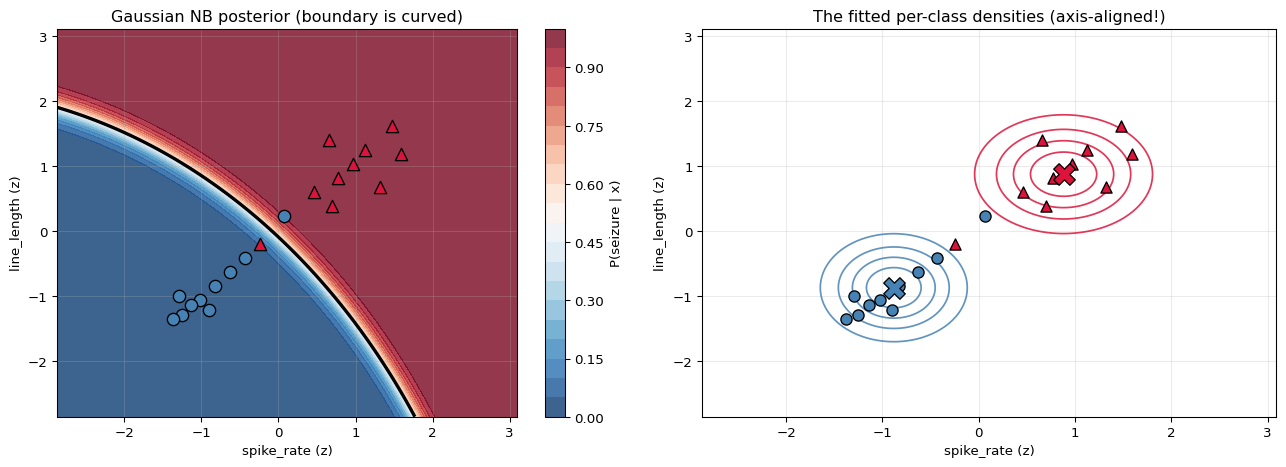

variances per class:
   class 0: [0.1808 0.2145]   equal across features
   class 1: [0.265  0.2594]   equal across features

class variances identical across classes? False  -> boundary is quadratic

Right panel: the contours are ellipses aligned with the AXES. They can
never tilt, because a diagonal covariance has no off-diagonal term. The
real data is tilted, and that mismatch is the naive assumption made visible.


In [9]:
gx, gy = np.meshgrid(np.linspace(Pz[:,0].min()-1.5, Pz[:,0].max()+1.5, 320),
                     np.linspace(Pz[:,1].min()-1.5, Pz[:,1].max()+1.5, 320))
G = np.column_stack([gx.ravel(), gy.ravel()])
lp_g = nb_log_posterior(G)
diff = (lp_g[:,1] - lp_g[:,0]).reshape(gx.shape)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))
pg = 1/(1+np.exp(-diff))
cf = axes[0].contourf(gx, gy, pg, levels=20, cmap="RdBu_r", alpha=.8, vmin=0, vmax=1)
axes[0].contour(gx, gy, diff, levels=[0], colors="k", linewidths=2.5)
plt.colorbar(cf, ax=axes[0], label="P(seizure | x)")
for c, (col, mk) in enumerate([("steelblue","o"), ("crimson","^")]):
    m = t2 == c
    axes[0].scatter(Pz[m,0], Pz[m,1], c=col, marker=mk, s=85, edgecolor="k", zorder=3)
axes[0].set(xlabel=feat2[0]+" (z)", ylabel=feat2[1]+" (z)",
            title="Gaussian NB posterior (boundary is curved)")
axes[0].grid(alpha=.25)

for c, col in enumerate(["steelblue", "crimson"]):
    dens = np.exp(-((G - means[c])**2 / (2*varis[c])).sum(axis=1)).reshape(gx.shape)
    axes[1].contour(gx, gy, dens, levels=5, colors=col, linewidths=1.3, alpha=.85)
    axes[1].scatter([means[c,0]], [means[c,1]], marker="X", s=260, c=col,
                    edgecolor="k", zorder=5)
for c, (col, mk) in enumerate([("steelblue","o"), ("crimson","^")]):
    m = t2 == c
    axes[1].scatter(Pz[m,0], Pz[m,1], c=col, marker=mk, s=70, edgecolor="k", zorder=3)
axes[1].set(xlabel=feat2[0]+" (z)", ylabel=feat2[1]+" (z)",
            title="The fitted per-class densities (axis-aligned!)")
axes[1].grid(alpha=.25)
plt.tight_layout(); plt.show()

print(f"variances per class:")
for c in range(2):
    print(f"   class {c}: {np.round(varis[c], 5)}   "
          f"{'equal across features' if np.allclose(varis[c,0], varis[c,1], atol=.05) else 'unequal'}")
print(f"\nclass variances identical across classes? "
      f"{np.allclose(varis[0], varis[1], atol=1e-6)}  -> boundary is "
      f"{'linear' if np.allclose(varis[0], varis[1], atol=1e-6) else 'quadratic'}")
print("\nRight panel: the contours are ellipses aligned with the AXES. They can")
print("never tilt, because a diagonal covariance has no off-diagonal term. The")
print("real data is tilted, and that mismatch is the naive assumption made visible.")

---
# 6. What the Naive Assumption Costs

The features here correlate above 0.9, so the independence assumption is plainly wrong.
What does that cost?

The key insight: **the assumption corrupts the probabilities much more than it corrupts
the decision.** Getting the arg max right only requires the *ranking* of the classes to
survive, and that is far more robust than the magnitudes.

Below, Gaussian NB (diagonal covariance) is compared with QDA, which fits the full
covariance and therefore makes no independence assumption.

In [10]:
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA
from sklearn.model_selection import LeaveOneOut, cross_val_score

nb = GaussianNB().fit(Pz, t2)
qda = QDA(reg_param=0.05).fit(Pz, t2)

print(f"{'model':>28}  {'train acc':>10}  {'LOO-CV':>9}  {'mean max prob':>14}")
print("-" * 68)
for name, mdl in [("Gaussian NB (independent)", nb), ("QDA (full covariance)", qda)]:
    cv = cross_val_score(mdl.__class__(**mdl.get_params()), Pz, t2,
                         cv=LeaveOneOut()).mean()
    pr = mdl.predict_proba(Pz)
    print(f"{name:>28}  {mdl.score(Pz,t2):>10.4f}  {cv:>9.4f}  "
          f"{pr.max(axis=1).mean():>14.6f}")
print("-" * 68)

print(f"\nagreement between the two on which class wins: "
      f"{(nb.predict(Pz) == qda.predict(Pz)).mean():.1%}")

pn, pq = nb.predict_proba(Pz)[:,1], qda.predict_proba(Pz)[:,1]
print(f"mean |difference| in P(y=1|x)                : {np.abs(pn-pq).mean():.4f}")
print(f"max  |difference| in P(y=1|x)                : {np.abs(pn-pq).max():.4f}")

print(f"\n{'id':>6}  {'NB P(y=1)':>11}  {'QDA P(y=1)':>12}  {'diff':>9}  {'same call?':>11}")
print("-" * 56)
for k in np.argsort(-np.abs(pn-pq))[:8]:
    print(f"{ep_ids[k]:>6}  {pn[k]:>11.6f}  {pq[k]:>12.6f}  {abs(pn[k]-pq[k]):>9.4f}  "
          f"{str(nb.predict(Pz)[k]==qda.predict(Pz)[k]):>11}")
print("-" * 56)

extreme = ((pn < 0.01) | (pn > 0.99)).mean()
extreme_q = ((pq < 0.01) | (pq > 0.99)).mean()
print(f"\npredictions more extreme than 1% / 99%:")
print(f"   Gaussian NB : {extreme:.1%}")
print(f"   QDA         : {extreme_q:.1%}")
print(f"\nNB is over-confident: multiplying correlated features counts the SAME")
print(f"evidence twice, so the log-posteriors are pushed further apart than the")
print(f"data justifies. The class that wins is usually still the right one, which")
print(f"is why the accuracy holds up while the probabilities should not be trusted.")

                       model   train acc     LOO-CV   mean max prob
--------------------------------------------------------------------
   Gaussian NB (independent)      0.9000     0.9000        0.994421
       QDA (full covariance)      0.9000     0.9000        0.972994
--------------------------------------------------------------------

agreement between the two on which class wins: 100.0%
mean |difference| in P(y=1|x)                : 0.0214
max  |difference| in P(y=1|x)                : 0.2443

    id    NB P(y=1)    QDA P(y=1)       diff   same call?
--------------------------------------------------------
  ep09     0.955221      0.710928     0.2443         True
  ep18     0.063270      0.151356     0.0881         True
  ep08     0.003197      0.041183     0.0380         True
  ep12     0.999905      0.974879     0.0250         True
  ep17     0.999940      0.986978     0.0130         True
  ep05     0.000169      0.010498     0.0103         True
  ep10     0.999999      0.9967

### Duplicating a feature makes the failure explicit

Copy one column so a feature appears twice. Nothing new has been measured, but Naive
Bayes counts the evidence twice over &mdash; and its confidence rises for no reason at all.

In [11]:
print(f"{'copies of feature 0':>21}  {'accuracy':>9}  {'mean max P':>12}  "
      f"{'# above 99%':>12}")
print("-" * 60)
for reps in (1, 2, 3, 5, 8):
    A = np.column_stack([Pz] + [Pz[:, [0]]] * (reps - 1))
    m = GaussianNB().fit(A, t2)
    pr = m.predict_proba(A)
    print(f"{reps:>21}  {m.score(A,t2):>9.4f}  {pr.max(axis=1).mean():>12.8f}  "
          f"{int((pr.max(axis=1) > .99).sum()):>12}")
print("-" * 60)
print("\nAccuracy barely moves; confidence marches to certainty. The extra columns")
print("carry zero new information - they are literally the same numbers - but the")
print("independence assumption has no way to notice.")
print("\nThis is the practical rule: use Naive Bayes for the DECISION, and do not")
print("read its probabilities as calibrated unless you have checked them.")

  copies of feature 0   accuracy    mean max P   # above 99%
------------------------------------------------------------
                    1     0.9000    0.99442089            18
                    2     0.9000    0.99841434            18
                    3     0.9000    0.99953763            20
                    5     0.9000    0.99995719            20
                    8     0.9000    0.99999857            20
------------------------------------------------------------

Accuracy barely moves; confidence marches to certainty. The extra columns
carry zero new information - they are literally the same numbers - but the
independence assumption has no way to notice.

This is the practical rule: use Naive Bayes for the DECISION, and do not
read its probabilities as calibrated unless you have checked them.


---
# 7. Other Likelihoods, and Zero Counts

Gaussian is only one choice. The framework is identical; only $P(x_j\mid y)$ changes:

| Variant | $P(x_j\mid y)$ | Used for |
|---|---|---|
| Gaussian | normal density | continuous features |
| Multinomial | $\propto \theta_{jc}^{x_j}$ | word counts |
| Bernoulli | $\theta_{jc}^{x_j}(1-\theta_{jc})^{1-x_j}$ | binary presence/absence |

For discrete variants a word never seen with a class gives $P = 0$, which annihilates the
entire product regardless of other evidence. **Laplace smoothing** prevents that:

$$P(x_j \mid y=c) = \frac{N_{jc} + \alpha}{N_c + \alpha\,d}$$

In [12]:
from sklearn.naive_bayes import MultinomialNB

vocab = ["spike", "sharp", "alpha", "artifact", "burst"]
docs = np.array([
    [3, 2, 0, 0, 2],
    [4, 1, 0, 1, 3],
    [2, 3, 1, 0, 1],
    [0, 0, 4, 2, 0],
    [1, 0, 3, 3, 0],
    [0, 1, 5, 1, 0],
])
dlab = np.array([1, 1, 1, 0, 0, 0])

print("word counts per report (a toy text problem)\n")
print(f"{'doc':>5}  " + "  ".join(f"{w:>9}" for w in vocab) + f"  {'class':>6}")
print("-" * 62)
for i in range(len(docs)):
    print(f"{'d'+str(i):>5}  " + "  ".join(f"{v:>9}" for v in docs[i]) + f"  {dlab[i]:>6}")
print("-" * 62)

print(f"\nword totals per class (note the zeros):\n")
print(f"{'class':>6}  " + "  ".join(f"{w:>9}" for w in vocab) + f"  {'total':>7}")
print("-" * 62)
tots = np.zeros((2, len(vocab)))
for c in range(2):
    tots[c] = docs[dlab == c].sum(axis=0)
    print(f"{c:>6}  " + "  ".join(f"{int(v):>9}" for v in tots[c]) +
          f"  {int(tots[c].sum()):>7}")
print("-" * 62)

print(f"\n'alpha' never appears in class 1. Without smoothing:")
print(f"   P(alpha | y=1) = 0/{int(tots[1].sum())} = 0")
print(f"   -> any report containing 'alpha' gets P(y=1) = 0 exactly,")
print(f"      no matter how many spike/burst words it also contains.\n")

print(f"{'alpha':>8}  " + "  ".join(f"{'P('+w[:5]+'|1)':>13}" for w in vocab))
print("-" * 78)
for a in (0.0, 0.01, 0.5, 1.0, 5.0):
    row = (tots[1] + a) / (tots[1].sum() + a*len(vocab))
    print(f"{a:>8.2f}  " + "  ".join(f"{v:>13.8f}" for v in row))
print("-" * 78)

test = np.array([[5, 2, 1, 0, 3]])
print(f"\na new report with counts {test[0].tolist()} (contains 'alpha' once):\n")
for a in (1e-10, 0.01, 1.0):
    m = MultinomialNB(alpha=a).fit(docs, dlab)
    pr = m.predict_proba(test)[0]
    print(f"   alpha = {a:<8}: P(y=0) = {pr[0]:.8f}, P(y=1) = {pr[1]:.8f} "
          f"-> class {int(pr.argmax())}")
print(f"\nWith almost no smoothing the single 'alpha' nearly vetoes class 1 despite")
print(f"five 'spike' counts. Smoothing restores the balance of evidence.")

word counts per report (a toy text problem)

  doc      spike      sharp      alpha   artifact      burst   class
--------------------------------------------------------------
   d0          3          2          0          0          2       1
   d1          4          1          0          1          3       1
   d2          2          3          1          0          1       1
   d3          0          0          4          2          0       0
   d4          1          0          3          3          0       0
   d5          0          1          5          1          0       0
--------------------------------------------------------------

word totals per class (note the zeros):

 class      spike      sharp      alpha   artifact      burst    total
--------------------------------------------------------------
     0          1          1         12          6          0       20
     1          9          6          1          1          6       23
----------------------------

---
# 8. Checking Against scikit-learn

In [13]:
sk = GaussianNB().fit(Pz, t2)

print(f"priors ours    : {np.round(priors, 10)}")
print(f"priors sklearn : {np.round(sk.class_prior_, 10)}")
print(f"MATCH: {np.allclose(priors, sk.class_prior_)}\n")

print(f"means ours    :\n{np.round(means, 10)}")
print(f"means sklearn :\n{np.round(sk.theta_, 10)}")
print(f"MATCH: {np.allclose(means, sk.theta_)}\n")

# sklearn adds a tiny epsilon to variances for numerical stability
print(f"variances ours    : {np.round(varis, 10).tolist()}")
print(f"variances sklearn : {np.round(sk.var_, 10).tolist()}")
print(f"sklearn's epsilon : {sk.epsilon_:.3e}")
print(f"MATCH (allowing for epsilon): {np.allclose(varis, sk.var_, atol=1e-8)}\n")

# our lpost is unnormalised: it differs from sklearn's normalised log-proba by
# log P(x), which is the SAME constant for both classes in a given row. So the
# class-to-class difference is the quantity that must agree exactly.
diff_ours = lpost[:, 1] - lpost[:, 0]
diff_sk = sk.predict_log_proba(Pz)[:, 1] - sk.predict_log_proba(Pz)[:, 0]
print(f"log-posterior DIFFERENCE (class1 - class0) MATCH: "
      f"{np.allclose(diff_ours, diff_sk, atol=1e-8)}")
print(f"   max discrepancy: {np.abs(diff_ours - diff_sk).max():.3e}")
print(f"   (the absolute values differ by log P(x), which we never computed)")
print(f"probabilities MATCH  : {np.allclose(probs, sk.predict_proba(Pz), atol=1e-10)}")
print(f"predictions MATCH    : {np.array_equal(pred, sk.predict(Pz))}")

print(f"\nthe single hand-computed point from section 4 ({ep_ids[9]}):")
print(f"   ours    P(y=1|x) = {post[1]:.10f}")
print(f"   sklearn P(y=1|x) = {sk.predict_proba(Pz[9][None,:])[0,1]:.10f}")
print(f"   MATCH: {np.isclose(post[1], sk.predict_proba(Pz[9][None,:])[0,1])}")

priors ours    : [0.5 0.5]
priors sklearn : [0.5 0.5]
MATCH: True

means ours    :
[[-0.8815 -0.8735]
 [ 0.8815  0.8735]]
means sklearn :
[[-0.8815 -0.8735]
 [ 0.8815  0.8735]]
MATCH: True

variances ours    : [[0.1808112467, 0.2144649543], [0.2649788516, 0.2593969651]]
variances sklearn : [[0.1808112477, 0.2144649553], [0.2649788526, 0.2593969661]]
sklearn's epsilon : 1.000e-09
MATCH (allowing for epsilon): True

log-posterior DIFFERENCE (class1 - class0) MATCH: True
   max discrepancy: 1.443e-07
   (the absolute values differ by log P(x), which we never computed)
probabilities MATCH  : True
predictions MATCH    : True

the single hand-computed point from section 4 (ep09):
   ours    P(y=1|x) = 0.9552210949
   sklearn P(y=1|x) = 0.9552210941
   MATCH: True


---
# 9. Summary

| Stage | Formula |
|---|---|
| Bayes' rule | $P(y\mid\mathbf{x}) \propto P(\mathbf{x}\mid y)P(y)$ |
| Naive assumption | $P(\mathbf{x}\mid y) = \prod_j P(x_j\mid y)$ |
| Gaussian likelihood | $\mathcal{N}(x_j;\,\mu_{jc},\,\sigma_{jc}^2)$ |
| Decision | $\arg\max_c \big[\log P(y{=}c) + \sum_j \log P(x_j\mid c)\big]$ |
| Smoothing | $(N_{jc}+\alpha)/(N_c+\alpha d)$ |
| Parameters | $2pk$ &mdash; linear in features, not exponential |
| Training cost | one pass, $O(np)$ |

**The one idea:** replace a joint distribution nobody can estimate with a product of
marginals anyone can. The assumption is almost always false, and the classifier is useful
anyway &mdash; because the arg max survives distortions that the probabilities do not.

**The honest caveat:** treat the output as a **ranking**, not a probability. The
feature-duplication experiment in section 6 shows confidence climbing toward certainty
while accuracy does not move at all.

**Where it still wins:** very high dimensions with little data (spam and text
classification), because it needs $O(p)$ parameters instead of $O(p^2)$, trains in a
single pass, and updates incrementally.

**What is deliberately left out:** Complement NB for imbalanced text, TF-IDF weighting,
the formal relationship to logistic regression as a generative/discriminative pair, and
LDA/QDA, which relax exactly the assumption examined here.